In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision import datasets, transforms

torch.manual_seed(42)

RESULTS = Path("../results")
RESULTS.mkdir(parents=True, exist_ok=True)

In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))

Training images: 60000
Test images: 10000


Image shape: torch.Size([1, 28, 28])
Label: 5
Minimum pixel: 0.0
Maximum pixel: 1.0


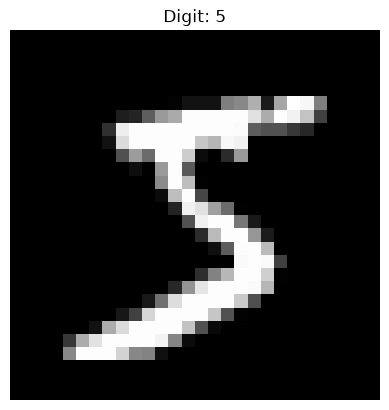

In [3]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Minimum pixel:", image.min().item())
print("Maximum pixel:", image.max().item())

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Digit: {label}")
plt.axis("off")
plt.show()

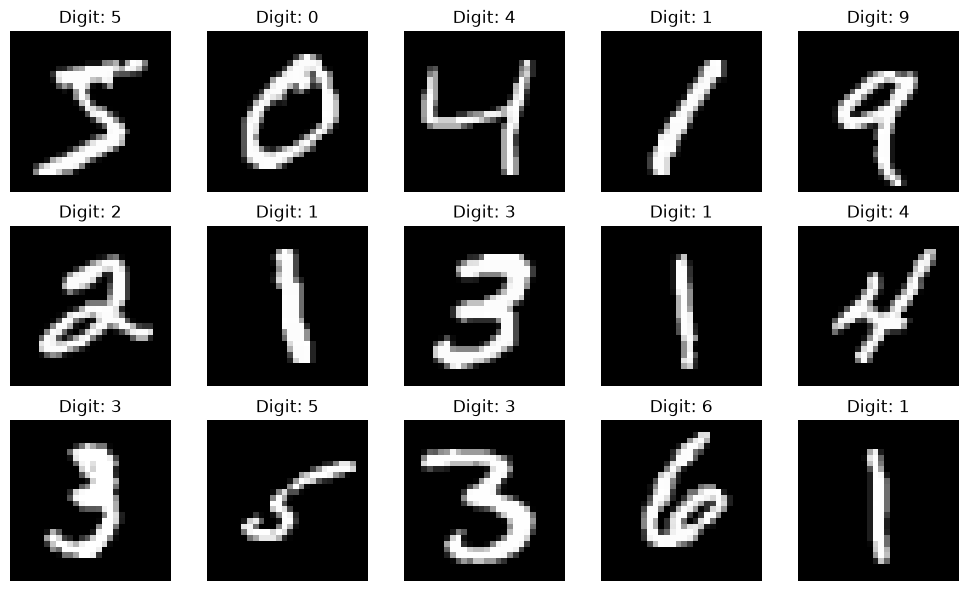

In [4]:
fig, axes = plt.subplots(3, 5, figsize=(10, 6))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Digit: {label}")
    ax.axis("off")

fig.tight_layout()
fig.savefig(RESULTS / "sample_digits.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

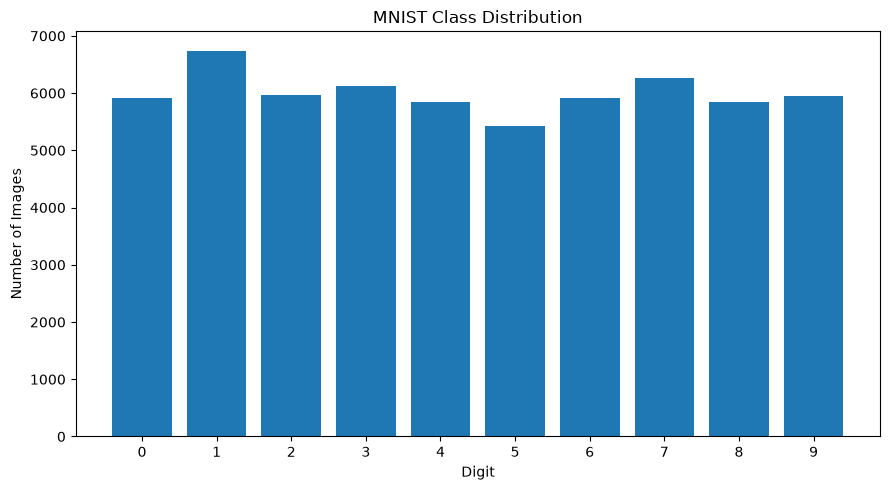

In [5]:
labels = train_dataset.targets.numpy()
counts = np.bincount(labels, minlength=10)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(range(10), counts)

ax.set_xlabel("Digit")
ax.set_ylabel("Number of Images")
ax.set_title("MNIST Class Distribution")
ax.set_xticks(range(10))

fig.tight_layout()
fig.savefig(RESULTS / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

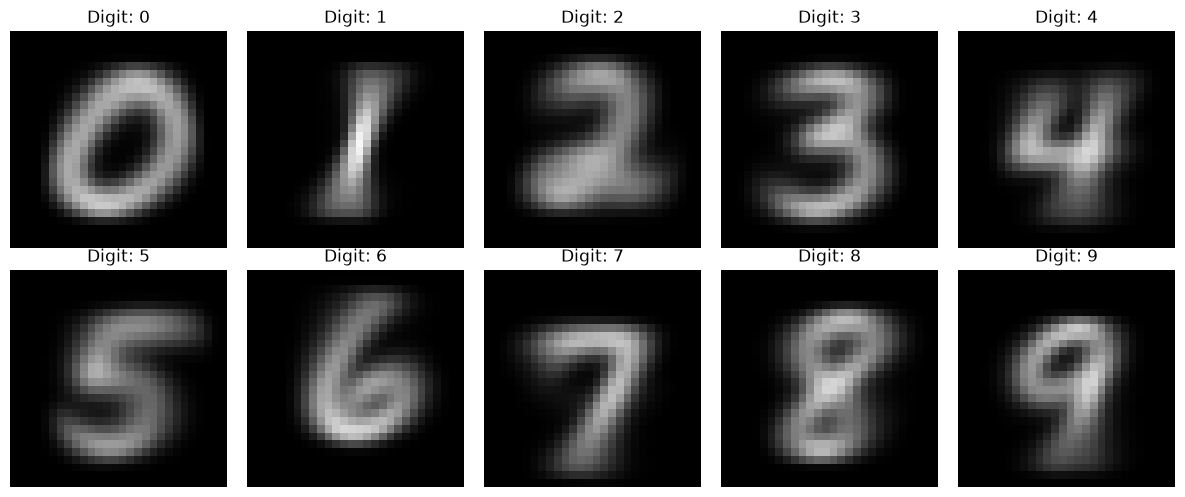

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for digit, ax in enumerate(axes.flat):
    indices = (train_dataset.targets == digit).nonzero().squeeze()
    images = train_dataset.data[indices].float() / 255.0
    average_image = images.mean(dim=0)

    ax.imshow(average_image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Digit: {digit}")
    ax.axis("off")

fig.tight_layout()
fig.savefig(RESULTS / "average_digits.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)